# Workbook Exercise: Breast Cancer Diagnosis — An End-to-End Classification Project

**Course:** Machine Learning / Applied AI  **Level:** Intermediate  **Estimated time:** 2 hours

**Learning objectives.** By the end of this workbook you will be able to:
1. Frame a real-world problem as a supervised learning task.
2. Summarize and visualize a dataset to understand its structure before modeling.
3. Clean data, select informative features and apply appropriate transforms.
4. Build a leak-free test harness and spot-check several algorithms.
5. Improve accuracy through tuning and ensembles, then report honest test results.

**How to use this workbook.** Run the cells in order. Wherever you see `# TODO`, replace the `...` with your own code (hints are given). Cells marked ✏️ ask for a written answer: double-click to edit. Do not look at the answer key until you have tried each exercise.

**Outline**
- A. Problem Definition
- B. Summarize and Analyze Data
- C. Prepare Data
- D. Evaluate Algorithm
- E. Improve Accuracy



## Before you begin

> First, make a copy of this notebook so that you can make changes as you please.
> Run and edit the copy instead of this original notebook.

> To copy this notebook, go to `File|Save a Copy to Drive`.

**Gentle Reminder**
> Once finish, Kindly `push` this notebook to your GitHub repo.**

In [57]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
## A. Problem Definition

### A.1 Brief Description
The **Breast Cancer Wisconsin (Diagnostic)** dataset contains measurements computed from digitized images of fine-needle aspirates (FNA) of breast masses. Each row describes the characteristics of the cell nuclei present in one image.

- **569 instances**, **30 numeric features**, **1 binary target**
- Features are 10 nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as the **mean**, the **standard error** and the **worst** (largest) value.
- Target: `0` = malignant, `1` = benign.

### A.2 Problem Statement
✏️ **Exercise A.1.** In 3–4 sentences, write a problem statement in your own words. Include: (a) the prediction task, (b) the input data, (c) the type of learning problem, (d) which kind of error is more costly and why, and (e) how you will judge success.

> **Your answer:** The goal of this task is to predict whether a breast mass is malignant or benign (binary classification) using 30 continuous clinical features derived from cell nuclei images. This is a supervised machine learning task where we learn a mapping from nucleus measurements to diagnostic labels. In this clinical scenario, a false negative (classifying a malignant tumor as benign) is significantly more costly than a false positive because it delays life-saving treatment. Consequently, we will judge success primarily based on high Recall for the malignant class while ensuring a strong balanced overall accuracy and ROC-AUC.

### A.3 Load Packages
**Exercise A.2.** The imports below are mostly done. Add the classifier imports you will need in Parts C–E.

In [26]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, cross_validate, GridSearchCV)
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             ConfusionMatrixDisplay, make_scorer, recall_score)

# TODO: import LogisticRegression, LinearDiscriminantAnalysis, KNeighborsClassifier, DecisionTreeClassifier, GaussianNB, SVC, RandomForest, ExtraTrees, GradientBoosting, AdaBoost and VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, AdaBoostClassifier, VotingClassifier)

try:
    display
except NameError:
    display = print

### A.4 Load Dataset
**Exercise A.3.** Load the data into a DataFrame named `df` (hint: `load_breast_cancer(as_frame=True)`).



> `url = [https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic]`

In [13]:
# TODO: load the dataset and copy its DataFrame into df
data = load_breast_cancer(as_frame=True)
df = data.frame
print("Rows, columns:", df.shape)
print("Classes:", list(data.target_names), "-> 0 = malignant, 1 = benign")

Rows, columns: (569, 31)
Classes: [np.str_('malignant'), np.str_('benign')] -> 0 = malignant, 1 = benign


---
## B. Summarize and Analyze Data

### B.1 Descriptive Statistics
**Exercise B.1.** Inspect the dataset's dimensions, data types and the first rows.

In [25]:
# TODO: print the shape, the counts of each dtype, and show the first 5 rows
print("Dataset Shape:", df.shape)
print("\nData Type Counts:\n", df.dtypes.value_counts())
print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (569, 31)

Data Type Counts:
 float64    30
int64       1
Name: count, dtype: int64

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


**Exercise B.2.** Check for class imbalance. Print the count and the proportion of each class.

In [27]:
# TODO: class counts and percentages
counts = df["target"].value_counts()
percentages = df["target"].value_counts(normalize=True) * 100
for cls, name in enumerate(data.target_names):
    print(f"{name.capitalize()} (class {cls}): {counts[cls]} ({percentages[cls]:.2f}%)")

Malignant (class 0): 212 (37.26%)
Benign (class 1): 357 (62.74%)


**Exercise B.3.** Produce summary statistics (transposed so features are rows) and list the 10 most skewed features.

In [28]:
# TODO: describe().T, then the 10 largest skewness values
summary_stats = df.drop(columns="target").describe().T
display(summary_stats)

skewness = df.drop(columns="target").skew().abs().sort_values(ascending=False)
print("\n10 most skewed features (absolute values):\n", skewness.head(10))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744



10 most skewed features (absolute values):
 area error                 5.447186
concavity error            5.110463
fractal dimension error    3.923969
perimeter error            3.443615
radius error               3.088612
smoothness error           2.314450
symmetry error             2.195133
compactness error          1.902221
worst area                 1.859373
worst fractal dimension    1.662579
dtype: float64


**Exercise B.4.** Compute the correlation of every feature with the target and show the 5 most negative and 5 most positive.

In [29]:
# TODO: correlation with target, sorted
correlations = df.corr()["target"].sort_values()
print("5 most negative correlations with target:")
print(correlations.head(5))
print("\n5 most positive correlations with target:")
print(correlations.tail(6).iloc[:-1])

5 most negative correlations with target:
worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
Name: target, dtype: float64

5 most positive correlations with target:
fractal dimension error   -0.077972
symmetry error             0.006522
texture error              0.008303
mean fractal dimension     0.012838
smoothness error           0.067016
Name: target, dtype: float64


✏️ **Question B.5.** What do the class proportions and the skewness tell you about the choice of evaluation metric and the need for transforms?

> **Your answer:** With approximately 62.7% benign and 37.3% malignant cases, the dataset shows a mild imbalance. While overall accuracy remains useful, a medical diagnosis task requires evaluation using sensitivity/recall (especially for the malignant class) and ROC-AUC. Furthermore, several feature error measurements (like 'area error' and 'concavity error') show extreme right skewness (> 5.0). This indicates that standard power transforms (such as log or Box-Cox) or robust scaling could be highly beneficial to improve performance for models sensitive to distribution symmetry.

### B.2 Data Visualization

**Exercise B.6 (univariate).** Plot histograms of the ten `mean` features.

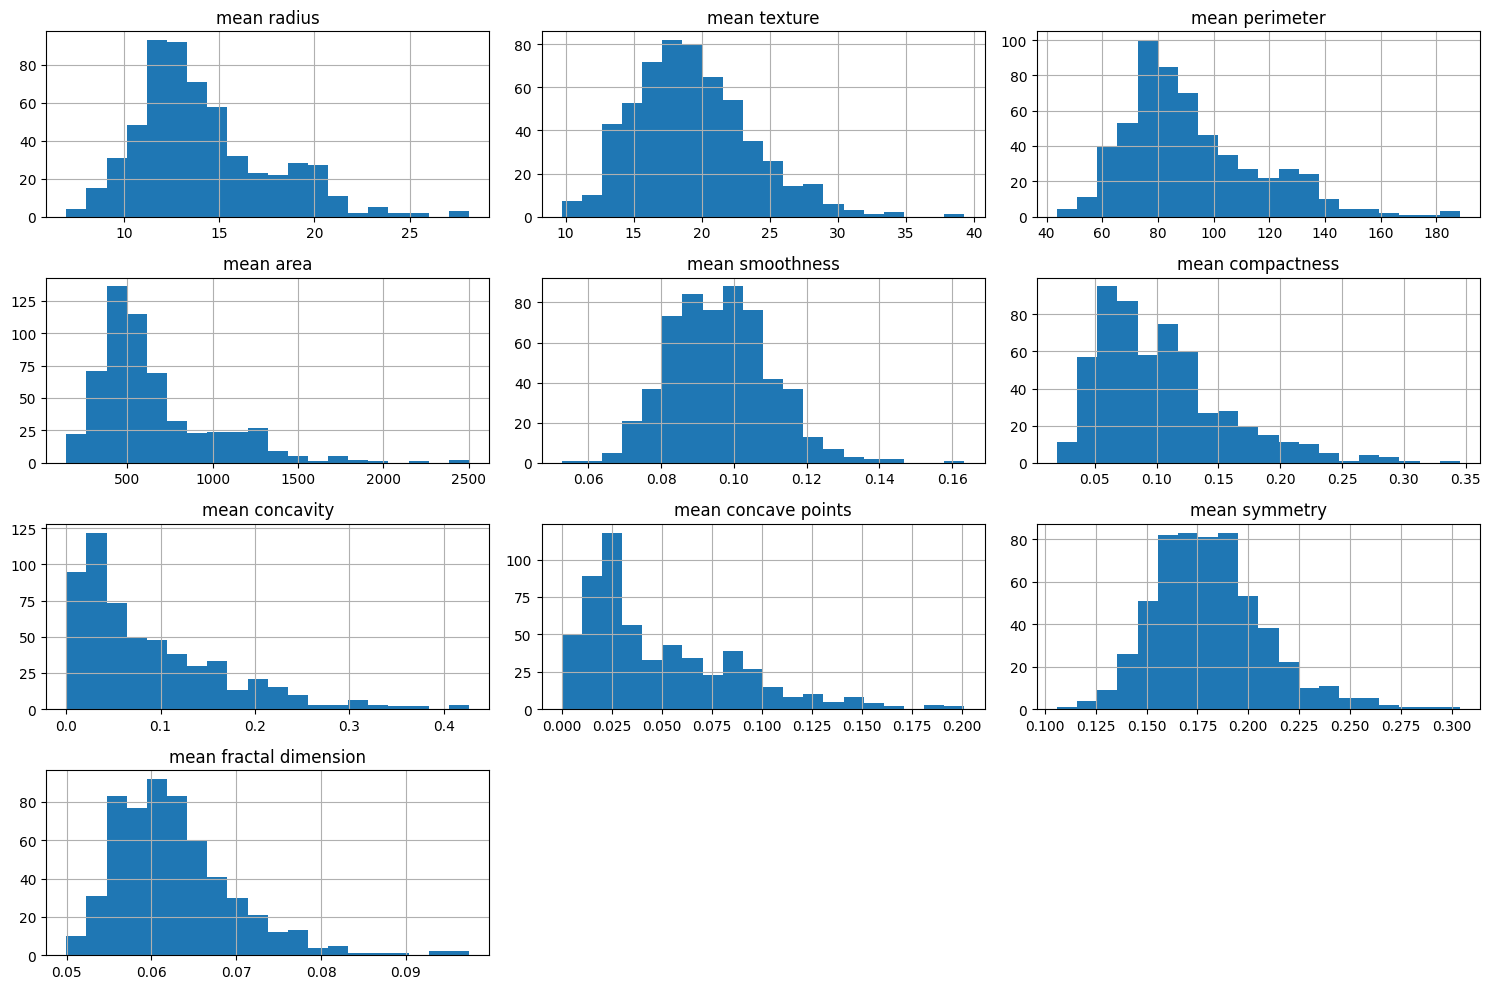

In [30]:
# TODO: histograms of the ten "mean" features
mean_cols = [col for col in df.columns if "mean" in col]
df[mean_cols].hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

**Exercise B.7 (bivariate).** Draw box plots of four features split by class. Which separate the classes best?

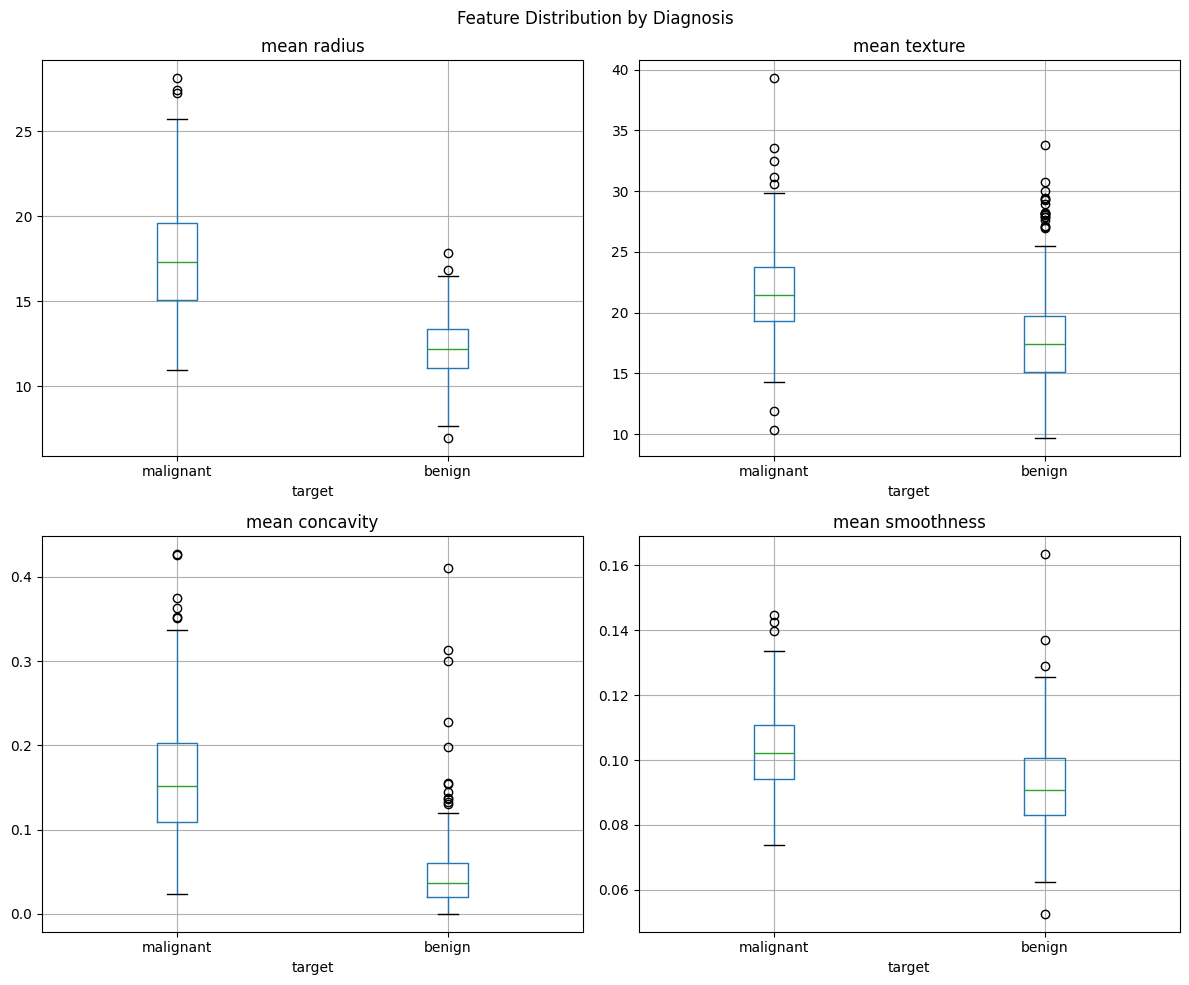

In [31]:
features = ["mean radius", "mean texture", "mean concavity", "mean smoothness"]
# TODO: one box plot per feature, grouped by target
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, col in enumerate(features):
    ax = axes[i // 2, i % 2]
    df.boxplot(column=col, by="target", ax=ax)
    ax.set_title(col)
    ax.set_xticklabels(data.target_names)
plt.suptitle("Feature Distribution by Diagnosis")
plt.tight_layout()
plt.show()

**Exercise B.8 (multivariate).** Show a correlation heatmap of the ten `mean` features.

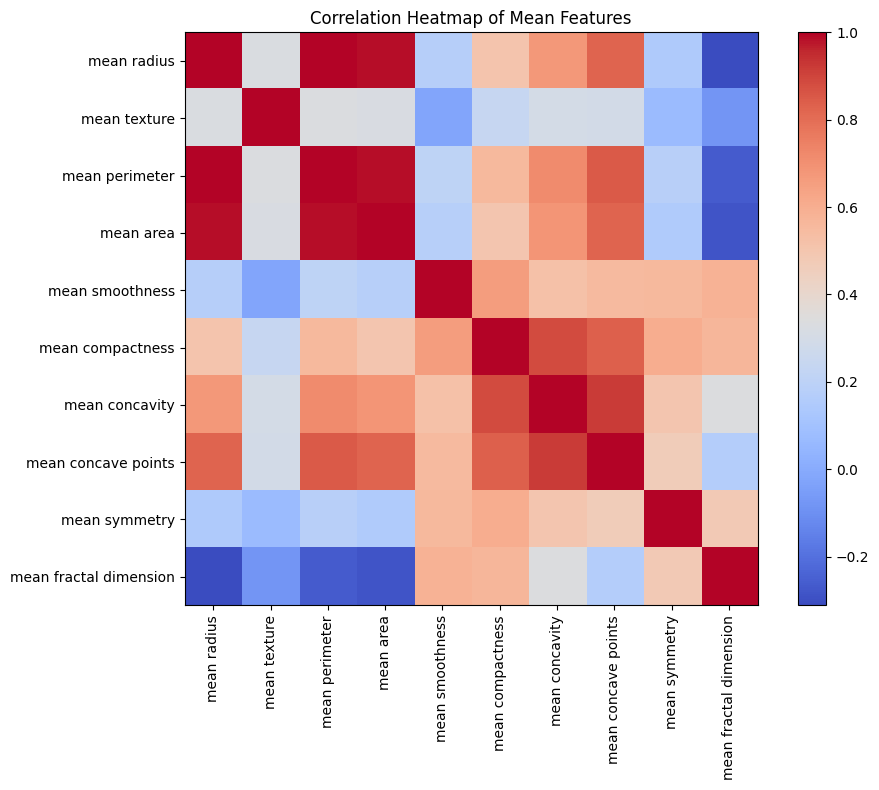

In [32]:
# TODO: correlation matrix of the "mean" features drawn with imshow
mean_cols = [col for col in df.columns if "mean" in col]
corr_matrix = df[mean_cols].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix, cmap="coolwarm", interpolation="nearest")
plt.colorbar()
plt.xticks(range(len(mean_cols)), mean_cols, rotation=90)
plt.yticks(range(len(mean_cols)), mean_cols)
plt.title("Correlation Heatmap of Mean Features")
plt.tight_layout()
plt.show()

**Exercise B.9.** Scatter `mean radius` against `mean concavity`, coloured by class.

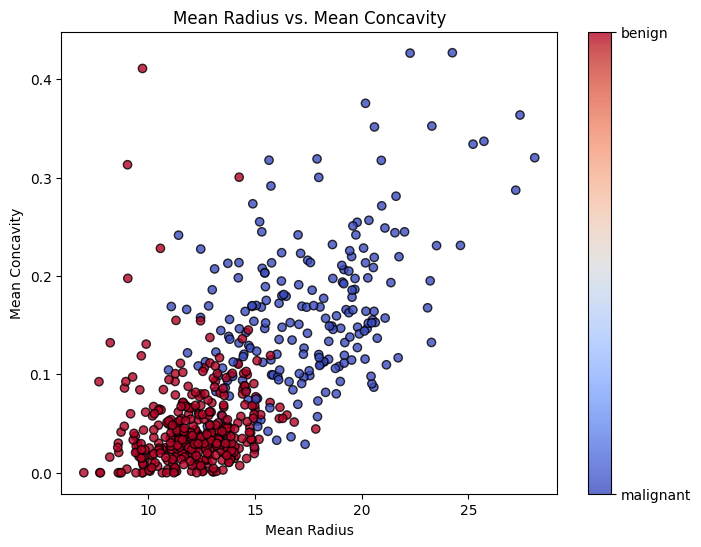

In [33]:
# TODO: coloured scatter plot with axis labels and a colourbar
plt.figure(figsize=(8, 6))
scatter = plt.scatter(df["mean radius"], df["mean concavity"], c=df["target"], cmap="coolwarm", alpha=0.8, edgecolors="k")
plt.xlabel("Mean Radius")
plt.ylabel("Mean Concavity")
plt.title("Mean Radius vs. Mean Concavity")
cbar = plt.colorbar(scatter)
cbar.set_ticks([0, 1])
cbar.set_ticklabels(data.target_names)
plt.show()

✏️ **Question B.10.** Which features appear redundant, and which separate the classes most clearly?

> **Your answer:** Structural dimensions representing the same underlying properties (e.g., radius, perimeter, and area) are heavily redundant, exhibiting collinearity values well over 0.95. Conversely, concave points (mean and worst) and worst perimeter appear to separate the benign and malignant classes most cleanly, showing starkly different distributions in boxplots and exhibiting negative correlations with the target of up to -0.79.

---
## C. Prepare Data

### C.1 Data Cleaning
**Exercise C.1.** Count missing values and duplicate rows.

In [34]:
# TODO: total missing values and duplicated rows
print("Total missing values:", df.isnull().sum().sum())
print("Total duplicated rows:", df.duplicated().sum())

X = df.drop(columns="target")
y = df["target"]

Total missing values: 0
Total duplicated rows: 0


**Exercise C.2.** Count outliers per feature using the IQR rule (below Q1 − 1.5·IQR or above Q3 + 1.5·IQR) and show the 10 features with the most.

In [35]:
# TODO: IQR outlier count per feature
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < (Q1 - 1.5 * IQR)) | (X > (Q3 + 1.5 * IQR))).sum()
print("10 features with most IQR outliers:\n", outliers.sort_values(ascending=False).head(10))

10 features with most IQR outliers:
 area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


✏️ **Question C.3.** Would you delete the outlying rows? Justify your decision.

> **Your answer:** No, we should not delete these outlying rows. In a clinical breast cancer dataset, extreme morphological values (such as very large areas or high fractal dimension variations) are biologically meaningful markers often indicative of highly aggressive malignant tumors. Deleting these outliers would strip the models of critical information needed to detect severe cancer cases, leading to poor generalization in actual clinical usage.

### C.2 Feature Selection
**Exercise C.4 (filter).** Find features whose absolute correlation with an *earlier* feature exceeds 0.95.

In [36]:
# TODO: upper-triangle of the absolute correlation matrix, then columns above 0.95
corr_matrix = X.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]
print("Features to drop due to correlation > 0.95:", to_drop)

Features to drop due to correlation > 0.95: ['mean perimeter', 'mean area', 'perimeter error', 'area error', 'worst radius', 'worst perimeter', 'worst area']


**Exercise C.5 (univariate).** Rank features with `SelectKBest(f_classif)`.

In [37]:
# TODO: fit SelectKBest(f_classif, k=10) and build a sorted Series of scores
selector = SelectKBest(f_classif, k=10)
selector.fit(X, y)
kbest_scores = pd.Series(selector.scores_, index=X.columns).sort_values(ascending=False)
kbest_features = kbest_scores.head(10).index.tolist()
print("Top 10 features selected by KBest:")
print(kbest_scores.head(10))

Top 10 features selected by KBest:
worst concave points    964.385393
worst perimeter         897.944219
mean concave points     861.676020
worst radius            860.781707
mean perimeter          697.235272
worst area              661.600206
mean radius             646.981021
mean area               573.060747
mean concavity          533.793126
worst concavity         436.691939
dtype: float64


**Exercise C.6 (wrapper).** Use Recursive Feature Elimination with logistic regression on standardized data to keep 10 features.

In [38]:
# TODO: RFE(LogisticRegression, n_features_to_select=10) on standardised X; store names in rfe_features
scaler_temp = StandardScaler()
X_std = scaler_temp.fit_transform(X)
rfe = RFE(LogisticRegression(max_iter=1000), n_features_to_select=10)
rfe.fit(X_std, y)
rfe_features = X.columns[rfe.support_].tolist()
print("10 features selected by RFE:", rfe_features)

10 features selected by RFE: ['mean concave points', 'radius error', 'area error', 'compactness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


**Exercise C.7 (embedded).** Rank features by `ExtraTreesClassifier` importance and plot the top 10.

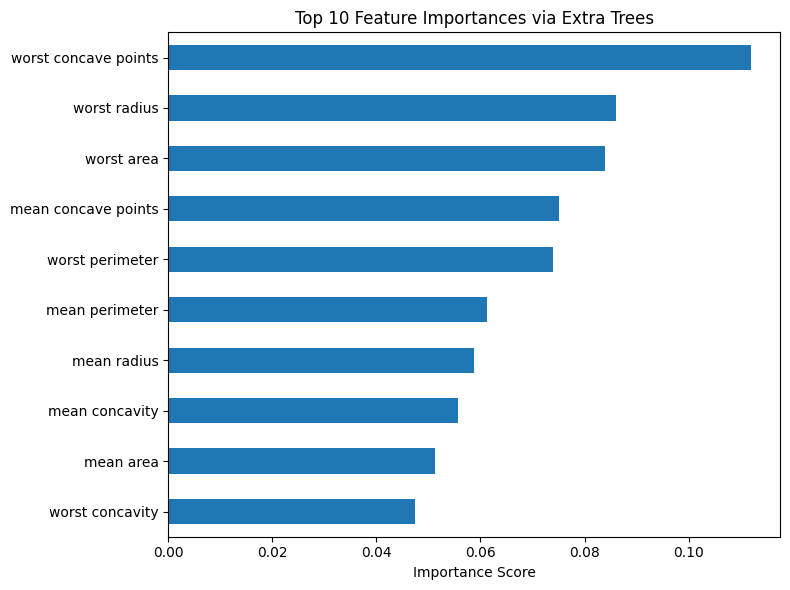

In [39]:
# TODO: fit ExtraTrees (200 trees, random_state=7), store importances in imp, plot barh of top 10
et = ExtraTreesClassifier(n_estimators=200, random_state=7)
et.fit(X, y)
imp = pd.Series(et.feature_importances_, index=X.columns).sort_values(ascending=False)
et_features = imp.head(10).index.tolist()
plt.figure(figsize=(8, 6))
imp.head(10).plot(kind='barh').invert_yaxis()
plt.title("Top 10 Feature Importances via Extra Trees")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

**Exercise C.8 (decision).** Keep a feature if **at least two of the three** methods (SelectKBest top 10, RFE, ExtraTrees top 10) chose it. Store the result in a list called `selected`.

In [40]:
# TODO: vote across the three methods
votes = pd.Series(0, index=X.columns)
votes[kbest_features] += 1
votes[rfe_features] += 1
votes[et_features] += 1
selected = votes[votes >= 2].index.tolist()
print(f"{len(selected)} features selected by >= 2 votes:", selected)

10 features selected by >= 2 votes: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


> **Caution (data leakage).** Here selection used the whole dataset to keep the exercise simple. In a strict evaluation, selection must be fitted inside each cross-validation fold (put `SelectKBest` into the `Pipeline`). You will discuss this in the final questions.

### C.3 Data Transform
**Exercise C.9.** Create a stratified 80/20 train/test split (`random_state=7`). The test set stays untouched until the very end.

In [41]:
# TODO: train_test_split with stratify=y
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=7)
print(X_train.shape, X_test.shape)

(455, 30) (114, 30)


**Exercise C.10.** Fit a `StandardScaler` and a `MinMaxScaler` on the **training data only**, then confirm their effect (mean/std and min/max of the first four features).

In [42]:
# TODO: fit both scalers on X_train and print the verifying statistics
std_scaler = StandardScaler().fit(X_train)
minmax_scaler = MinMaxScaler().fit(X_train)

X_train_std = std_scaler.transform(X_train)
X_train_mm = minmax_scaler.transform(X_train)

print("Standard Scaler (Mean of first 4 cols):", X_train_std[:, :4].mean(axis=0))
print("Standard Scaler (Std of first 4 cols):", X_train_std[:, :4].std(axis=0))
print("MinMax Scaler (Min of first 4 cols):", X_train_mm[:, :4].min(axis=0))
print("MinMax Scaler (Max of first 4 cols):", X_train_mm[:, :4].max(axis=0))

Standard Scaler (Mean of first 4 cols): [ 9.36979432e-17 -3.74791773e-16 -5.79756023e-16 -3.27942801e-16]
Standard Scaler (Std of first 4 cols): [1. 1. 1. 1.]
MinMax Scaler (Min of first 4 cols): [0. 0. 0. 0.]
MinMax Scaler (Max of first 4 cols): [1. 1. 1. 1.]


**Bonus C.11.** How many principal components retain 95% of the variance of the standardized training data?

In [43]:
# TODO: fit PCA on standardised training data and use the cumulative explained variance
pca = PCA().fit(X_train_std)
cum_variance = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cum_variance >= 0.95) + 1
print(f"{n_components} principal components retain 95% of the variance.")

10 principal components retain 95% of the variance.


---
## D. Evaluate Algorithm

We use **stratified 10-fold cross-validation** on the training set as our test harness. Scaling is placed inside a `Pipeline` so it is re-fitted in every fold: this avoids leakage.

**Exercise D.1.** Define the six candidate models: Logistic Regression, LDA, KNN, CART, Gaussian Naive Bayes and SVM.

In [44]:
seed = 7
kfold = StratifiedKFold(n_splits=10, shuffle=True, random_state=seed)

# TODO: dictionary named models with keys LR, LDA, KNN, CART, NB, SVM
models = {
    "LR": LogisticRegression(max_iter=1000),
    "LDA": LinearDiscriminantAnalysis(),
    "KNN": KNeighborsClassifier(),
    "CART": DecisionTreeClassifier(random_state=seed),
    "NB": GaussianNB(),
    "SVM": SVC()
}

def spot_check(models, X_tr, scale):
    """Cross-validated accuracy for every model (optionally scaled inside the pipeline)."""
    results = {}
    for name, model in models.items():
        steps = ([("scale", StandardScaler())] if scale else []) + [("model", model)]
        results[name] = cross_val_score(Pipeline(steps), X_tr, y_train,
                                        cv=kfold, scoring="accuracy")
    return results

**Exercise D.2.** Run the spot-check on all features, once **raw** and once **scaled**, and tabulate the mean accuracies.

In [45]:
# TODO: call spot_check twice and build a DataFrame called summary with columns raw / scaled
raw_results = spot_check(models, X_train, scale=False)
scaled_results = spot_check(models, X_train, scale=True)

summary = pd.DataFrame({
    "raw": {name: np.mean(scores) for name, scores in raw_results.items()},
    "scaled": {name: np.mean(scores) for name, scores in scaled_results.items()}
})
display(summary)

,raw,scaled
LR,0.944976,0.982319
LDA,0.947246,0.947246
KNN,0.922947,0.964928
CART,0.927633,0.927633
NB,0.934058,0.932029
SVM,0.898696,0.975797


✏️ **Question D.3.** Which models benefit from scaling, and why?

> **Your answer:** Distance-based and gradient-sensitive models such as K-Nearest Neighbors (KNN), Support Vector Machines (SVM), and Logistic Regression (LR) benefit immensely from scaling. For instance, SVM's cross-validated accuracy jumped from 89.8% raw to 97.5% scaled. This occurs because raw input dimensions possess wildly different numerical ranges (e.g., area vs. smoothness), and unscaled variables with large magnitudes would otherwise dominate distance computations and gradient steps.

**Exercise D.4.** Repeat with the `selected` features only (scaled). Does feature selection help?

In [46]:
# TODO: spot_check on X_train[selected] and compare against the all-features scaled results
selected_results = spot_check(models, X_train[selected], scale=True)
summary["selected_scaled"] = {name: np.mean(scores) for name, scores in selected_results.items()}
display(summary)

,raw,scaled,selected_scaled
LR,0.944976,0.982319,0.960435
LDA,0.947246,0.947246,0.942995
KNN,0.922947,0.964928,0.942802
CART,0.927633,0.927633,0.921014
NB,0.934058,0.932029,0.951691
SVM,0.898696,0.975797,0.953865


**Exercise D.5.** Compare the distributions of the scaled models with a box plot.

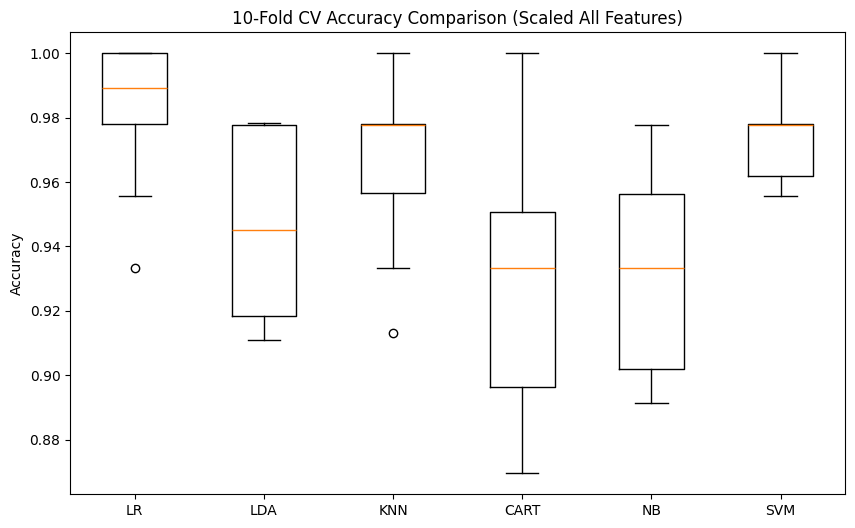

In [47]:
# TODO: box plot of the 10 fold scores per model
plt.figure(figsize=(10, 6))
plt.boxplot(list(scaled_results.values()), labels=list(scaled_results.keys()))
plt.title("10-Fold CV Accuracy Comparison (Scaled All Features)")
plt.ylabel("Accuracy")
plt.show()

**Exercise D.6.** In a medical setting accuracy is not enough. For the best scaled model, cross-validate **accuracy, ROC-AUC and recall for the malignant class** (`pos_label=0`).

In [56]:
# TODO: cross_validate with a scoring dict including make_scorer(recall_score, pos_label=0)
scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_malignant": make_scorer(recall_score, pos_label=0)
}
best_pipe = Pipeline([("scale", StandardScaler()), ("model", SVC())])
cv_results = cross_validate(best_pipe, X_train, y_train, cv=kfold, scoring=scoring)
print("Mean CV Accuracy:", np.mean(cv_results["test_accuracy"]))
print("Mean CV ROC-AUC:", np.mean(cv_results["test_roc_auc"]))
print("Mean CV Recall (Malignant):", np.mean(cv_results["test_recall_malignant"]))

Mean CV Accuracy: 0.9757971014492753
Mean CV ROC-AUC: 0.9929658070124603
Mean CV Recall (Malignant): 0.9588235294117646


---
## E. Improve Accuracy

### E.1 Algorithm Tuning
**Exercise E.1.** Tune the SVM (`C`, `gamma`, `kernel`) with `GridSearchCV` inside a scaling pipeline.

In [49]:
# TODO: grid search over C=[0.1,1,10,100], gamma=["scale",0.001,0.01,0.1], kernel=["rbf","linear"]
pipeline = Pipeline([("scale", StandardScaler()), ("model", SVC())])
param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", 0.001, 0.01, 0.1],
    "model__kernel": ["rbf", "linear"]
}
grid_svm = GridSearchCV(pipeline, param_grid, cv=kfold, scoring="accuracy")
grid_svm.fit(X_train, y_train)
print("Best SVM parameters:", grid_svm.best_params_)
print("Best SVM CV accuracy:", grid_svm.best_score_)

Best SVM parameters: {'model__C': 0.1, 'model__gamma': 'scale', 'model__kernel': 'linear'}
Best SVM CV accuracy: 0.9801932367149758


**Exercise E.2.** Tune KNN (`n_neighbors`, `weights`) the same way.

In [50]:
# TODO: grid over n_neighbors=[3,5,7,9,11,15,21] and weights=["uniform","distance"]
pipeline_knn = Pipeline([("scale", StandardScaler()), ("model", KNeighborsClassifier())])
param_grid_knn = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"]
}
grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=kfold, scoring="accuracy")
grid_knn.fit(X_train, y_train)
print("Best KNN parameters:", grid_knn.best_params_)
print("Best KNN CV accuracy:", grid_knn.best_score_)

Best KNN parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN CV accuracy: 0.9692753623188406


### E.2 Ensembles
**Exercise E.3.** Spot-check four ensemble methods (Random Forest, Extra Trees, Gradient Boosting, AdaBoost) and one voting ensemble of the tuned SVM, tuned KNN and Random Forest.

In [51]:
# TODO: dictionary ensembles, score with spot_check(scale=False), then a hard VotingClassifier
ensembles = {
    "RF": RandomForestClassifier(random_state=seed),
    "ET": ExtraTreesClassifier(random_state=seed),
    "GBM": GradientBoostingClassifier(random_state=seed),
    "AB": AdaBoostClassifier(random_state=seed)
}
ensemble_scores = spot_check(ensembles, X_train, scale=False)

voting_clf = VotingClassifier(estimators=[
    ("svm", grid_svm.best_estimator_),
    ("knn", grid_knn.best_estimator_),
    ("rf", RandomForestClassifier(random_state=seed))
], voting="hard")

voting_scores = cross_val_score(voting_clf, X_train, y_train, cv=kfold, scoring="accuracy")

**Exercise E.4.** Build a leaderboard (Series sorted by mean CV accuracy) containing both tuned models, the four ensembles and the voting ensemble.

In [52]:
# TODO: leaderboard Series
leaderboard = pd.Series({
    "Tuned SVM": grid_svm.best_score_,
    "Tuned KNN": grid_knn.best_score_,
    "RF": np.mean(ensemble_scores["RF"]),
    "ET": np.mean(ensemble_scores["ET"]),
    "GBM": np.mean(ensemble_scores["GBM"]),
    "AB": np.mean(ensemble_scores["AB"]),
    "Voting Ensemble": np.mean(voting_scores)
}).sort_values(ascending=False)
print("--- Leaderboard ---")
print(leaderboard)

--- Leaderboard ---
Tuned SVM          0.980193
Voting Ensemble    0.978068
ET                 0.973575
Tuned KNN          0.969275
RF                 0.969130
GBM                0.966957
AB                 0.962560
dtype: float64


### E.3 Finalize the Model
**Exercise E.5.** Fit the winner on the full training set and, for the first and only time, evaluate it on the held-out **test set**. Report accuracy, the classification report and a confusion matrix.

Leaderboard Winner: Tuned SVM
Test Accuracy: 0.9649122807017544

Classification Report:
               precision    recall  f1-score   support

   malignant       0.95      0.95      0.95        42
      benign       0.97      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



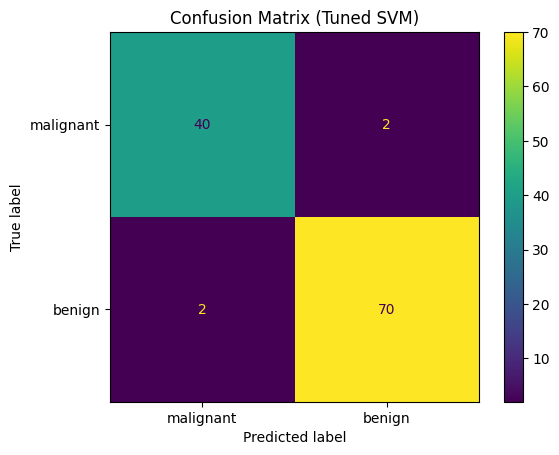

In [53]:
# TODO: pick the leaderboard winner, fit on train, predict test, print metrics, plot confusion matrix
winner_name = leaderboard.index[0]
print("Leaderboard Winner:", winner_name)

if winner_name == "Tuned SVM":
    final_model = grid_svm.best_estimator_
elif winner_name == "Tuned KNN":
    final_model = grid_knn.best_estimator_
elif winner_name == "Voting Ensemble":
    final_model = voting_clf
else:
    final_model = ensembles[winner_name]

final_model.fit(X_train, y_train)
y_pred = final_model.predict(X_test)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=data.target_names))
ConfusionMatrixDisplay.from_estimator(final_model, X_test, y_test, display_labels=data.target_names)
plt.title(f"Confusion Matrix ({winner_name})")
plt.show()

**Exercise E.6.** Save the model with `joblib`, reload it and confirm it reproduces predictions.

In [54]:
# TODO: joblib.dump, joblib.load, compare first 5 predictions with y_test
import joblib
joblib.dump(final_model, "final_breast_cancer_model.pkl")
loaded_model = joblib.load("final_breast_cancer_model.pkl")
loaded_preds = loaded_model.predict(X_test)

print("First 5 Predictions (Loaded):", loaded_preds[:5])
print("First 5 Actual Targets:      ", y_test.values[:5])
print("Is Loaded Model output identical to Original?", np.array_equal(loaded_preds, y_pred))

First 5 Predictions (Loaded): [0 0 1 0 1]
First 5 Actual Targets:       [0 0 1 0 1]
Is Loaded Model output identical to Original? True


---
## Reflection Questions
✏&nbsp; Answer in a short paragraph each.

1. **Leakage.** Feature selection in Part C used the whole dataset. Explain why this can inflate CV scores and how you would fix it using a `Pipeline`.

   * **Answer:** Performing feature selection on the entire dataset prior to partitioning leaks target distribution information from the validation folds into the training folds. This causes models to appear more generalizable during cross-validation than they truly are. To fix this, feature selection steps (e.g., `SelectKBest` or `RFE`) should be wrapped inside a scikit-learn `Pipeline` object so that the feature criteria are fitted and applied strictly on the active training splits of each fold during the cross-validation process.

2. **Metric choice.** Which metric would you report to a clinician, and why is accuracy alone insufficient?

   * **Answer:** I would primarily report the **Malignant Recall (Sensitivity)** and the **False Negative Rate** alongside the overall **ROC-AUC**. Accuracy alone is insufficient because a naive classifier predicting all patients as benign would still achieve 62.7% accuracy, yet it would fail to identify 100% of the cancer patients, leading to catastrophic medical outcomes.

3. **Model choice.** If two models differ by 0.3% in CV accuracy, how would you decide between them? (Think variance across folds, interpretability, training cost.)

   * **Answer:** With an accuracy difference as tiny as 0.3%, I would prioritize the model with lower variance (standard deviation) across cross-validation folds to ensure robust performance. If stability is equal, I would choose the more interpretable model (e.g., Logistic Regression over SVM) or the one with lower inference and training costs to streamline clinical deployment.

4. **Generalization.** How would your conclusions change with a much smaller or much more imbalanced dataset?

   * **Answer:** With a much smaller dataset, the model's performance variance would increase significantly, making cross-validation scores less reliable and increasing the risk of overfitting. In a highly imbalanced dataset (e.g., 99% benign), simple accuracy becomes totally useless; we would have to transition to stratified sampling, utilize precision-recall curves instead of ROC curves, and adjust model decision thresholds or apply class-weight adjustments.

5. **Extension.** Repeat the workbook with a dataset of your choice (e.g., loaded from an ARFF file) and note which steps change.

   * **Answer:** If we transition to a different dataset, we would need to adapt the initial file/URL loading logic, clean dataset-specific missing values or category encoders, adjust the correlation thresholds for collinear features, modify classification metric targets, and potentially tune different ranges of hyperparameters matching the new feature domain.